# Detección de anomalías en la producción agrícola del Perú
## Encuesta Nacional Agropecuaria (ENA – INEI), 2014-2025

**Universidad Nacional del Altiplano – Puno** · Facultad de Ingeniería Estadística e Informática · Ciencia de Datos I (VIII semestre) · Docente: Fred Torres Cruz

**Integrantes:** Rommel Absalón Pacori Vera · Milton Flores Flores · Víctor Serapio Aquine Jimenez

**Problema.** Cada año la ENA registra, para cada productor, los cultivos que cosechó: superficie, producción y lo que vendió. Un registro con un rendimiento o un precio muy distinto al de su mismo cultivo, año y región puede ser un error de digitación, una confusión de unidades o un caso real fuera de lo común. Queremos **detectar automáticamente esos registros** con métodos no supervisados y **validar** la detección con todo el rango 2015-2025.

El trabajo se organiza en 5 etapas; cada una es una función del módulo `ena_anomalias.py`:

| Etapa | Funciones |
|---|---|
| 1. Carga e integración | `leer_sav`, `agregar_factor_parcela`, `leer_2025`, `integrar` |
| 2. Limpieza | `limpiar` |
| 3. Variables | `crear_variables`, `z_robusto` |
| 4. Modelos | `detectar_z`, `detectar_dbscan`, `elegir_k`, `detectar_kmeans`, `detectar_iforest`, `detectar_todo` |
| 5. Validación | `validar_silueta`, `validar_reglas`, `validar_inyeccion`, `validar_temporal` |


In [1]:
# Configuración: rutas de los datos (cambiar si se ejecuta en otra computadora)
RUTA_SAV  = '/home/user/data/sav/ENA_2014_2024.sav'          # E:\\Dataset\\2014-2024\\ENA_2014_2024.zip (descomprimido)
RUTA_2025 = '/mnt/user-data/uploads/Dataset/2025'             # E:\\Dataset\\2025 (los 21 zip tal cual)
CARPETA   = '/mnt/project-files/anomalias_ena'

import sys, os, time, warnings; warnings.filterwarnings('ignore')
sys.path.insert(0, CARPETA)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import ena_anomalias as ea
os.makedirs(f'{CARPETA}/figuras', exist_ok=True); os.makedirs(f'{CARPETA}/resultados', exist_ok=True)
pd.set_option('display.width', 180); pd.set_option('display.max_columns', 30)
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110})

## Etapa 1 · Carga e integración

* **2014-2024:** un solo archivo SPSS de 14,7 GB (3 843 598 filas × 1 704 variables; todos los capítulos apilados). Solo leemos las columnas del capítulo 200 (cultivos cosechados) y de la parcela.
* **2025:** 21 zip con un CSV por capítulo; el capítulo 200 está en `03_CAP200AB.csv` (módulo 1895).
* Las variables tienen el mismo nombre en ambas fuentes, así que se unen con `integrar`.
* **Superficie en hectáreas.** El productor declara la superficie del cultivo en la unidad local de su parcela (m², topo, yugada…). El INEI publica la conversión (`P217_SUP_ha`) en todos los años **menos 2015 y 2018**; para esos dos años la reconstruimos con el factor de la parcela (`agregar_factor_parcela`).

In [2]:
t = time.time()
d_14_24 = ea.leer_sav(RUTA_SAV)
d_25 = ea.leer_2025(RUTA_2025)
datos = ea.integrar(d_14_24, d_25)
print(f'Filas leídas: {len(datos):,}  ({time.time()-t:.0f} s)')
datos.groupby('ANIO').size().rename('filas (todas las secciones)').to_frame().T

Filas leídas: 4,002,345  (191 s)


ANIO,2014,2015,2016,2017,2018,2019,2021,2022,2023,2024,2025
filas (todas las secciones),196962,251795,281677,284751,368718,366615,374116,291667,582748,844549,158747


**Comprobación de la reconstrucción de la superficie:** en los años donde el INEI sí publica las hectáreas, nuestro cálculo con el factor de la parcela debe dar lo mismo.

In [3]:
chk = datos[datos.P203.notna() & datos.P217_SUP_ha.notna() & datos.fac_parcela.notna()].copy()
recon = ea._entero_decimal(chk.P217_SUP_1, chk.P217_SUP_2) * pd.to_numeric(chk.fac_parcela)
oficial = pd.to_numeric(chk.P217_SUP_ha)
coincide = np.isclose(recon, oficial, rtol=0.01)
print(f'Registros comparados: {len(chk):,} · coinciden con el INEI: {coincide.mean():.2%}')
pd.Series(coincide).groupby(chk.ANIO.values).mean().rename('coincidencia').to_frame().T

Registros comparados: 783,865 · coinciden con el INEI: 100.00%


,2016,2017,2019,2021,2022,2023,2024
coincidencia,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## Etapa 2 · Limpieza

Cada paso deja constancia de cuántos registros quedan (embudo de limpieza). Decisiones:
1. Solo las filas de la sección 200A (cultivo cosechado con número de cultivo).
2. Solo encuestas completas (`RESFIN = 1`).
3. **2014 se excluye del modelo**: el INEI no publicó superficie, cantidad ni valor de venta ese año (las columnas vienen vacías).
4. Los números vienen partidos en entero + decimales en texto (`'069'` = 0,069): se reconstruyen.
5. Se eliminan códigos de relleno (99 999 999), ceros y duplicados.
6. Se conservan los cultivos con 30 registros o más en el año (para comparar contra su grupo).

In [4]:
limpio, embudo = ea.limpiar(datos)
embudo.to_csv(f'{CARPETA}/resultados/embudo_limpieza.csv', index=False)
embudo

,Paso,Registros,Nota
0,Filas con nombre de cultivo (todas las secciones),1658156,
1,Registros de cultivos cosechados (sección 200A...,1493391,
2,Solo encuestas completas (RESFIN = 1),1492147,
3,Sin 2014 (INEI no publicó cantidades ni superf...,1413650,
4,"Con superficie, cantidad y equivalencia en kg",1267692,
5,Sin códigos de relleno (99 999 999 y similares),1267547,145 eliminados
6,Superficie y producción mayores que cero,1267547,
7,"Sin registros duplicados (mismo productor, par...",1266671,
8,Cultivos con 30 registros o más en el año,1250406,


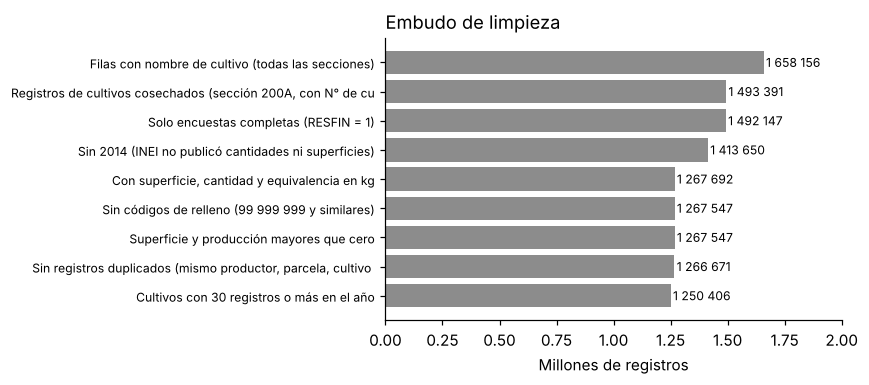

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.6))
e = embudo.iloc[::-1]
ax.barh(range(len(e)), e.Registros/1e6, color='0.55')
ax.set_yticks(range(len(e)), [p[:60] for p in e.Paso], fontsize=8)
for i, v in enumerate(e.Registros): ax.text(v/1e6 + 0.01, i, f'{v:,}'.replace(',', ' '), va='center', fontsize=8)
ax.set_xlabel('Millones de registros'); ax.set_xlim(0, 2); ax.set_title('Embudo de limpieza', loc='left')
plt.tight_layout(); plt.savefig(f'{CARPETA}/figuras/f1_embudo.png', dpi=200); plt.show()

## Etapa 3 · Selección y construcción de variables

No usamos las cifras en bruto: un saco de papa y una tonelada de café no se comparan. Construimos tres variables con sentido agronómico y las comparamos **contra su propio contexto** (mismo cultivo, año y región natural):

| Variable | Fórmula | Por qué |
|---|---|---|
| Rendimiento | producción (kg) / superficie cosechada (ha) | capta errores en producción o superficie |
| Precio por kg | valor de venta / kg vendidos | capta errores en valor o cantidad vendida |
| Superficie | ha cosechadas | capta superficies imposibles para un productor |

Se pasan a logaritmo y se convierten en **z robusto**: `(x − mediana) / (1,4826 × MAD)`, calculado dentro de cultivo × año × región (o cultivo × año si el grupo tiene menos de 30). Usamos mediana y MAD porque, a diferencia de la media y la desviación, **no se dejan arrastrar por las mismas anomalías** que queremos encontrar. Quien no vende queda con z de precio = 0 (neutral).

In [6]:
dv = ea.crear_variables(limpio)
dv[['rend_kg_ha', 'precio_kg', 'area_ha', 'z_rend', 'z_precio', 'z_area']].describe(percentiles=[.01, .5, .99]).round(2)

,rend_kg_ha,precio_kg,area_ha,z_rend,z_precio,z_area
count,1250406.00,542761.00,1250406.00,1250406.00,1250406.00,1250406.00
mean,10457.88,2.82,1.91,-0.09,-0.00,-0.01
std,30368.59,3.46,66.08,1.15,0.81,1.15
min,0.10,0.00,0.00,-20.38,-26.02,-32.00
1%,288.00,0.10,0.00,-3.37,-2.42,-2.92
50%,6428.57,1.62,0.10,0.00,0.00,0.00
99%,70353.32,19.46,24.00,2.47,2.38,2.80
max,30000000.00,58.82,50000.00,15.27,30.46,63.52


## Etapa 4 · Modelos

Usamos los mismos cuatro métodos del artículo de referencia (Herreros-Martínez et al., 2024) y los combinamos por votación:

* **Z-score robusto:** anómalo si |z| de rendimiento o de precio > 3,5 (criterio de Iglewicz y Hoaglin).
* **DBSCAN:** anómalo si queda como *ruido* (sin vecindario denso). Para que corra con 1,25 millones de filas se agrupan puntos casi iguales y se usan pesos.
* **k-Means:** anómalo si está en el 1 % más lejano del centro de su grupo; *k* se elige con la silueta.
* **Isolation Forest:** anómalo si se aísla con pocos cortes (1 % de contaminación).
* **Votación:** un registro es **anomalía final** si lo marcan **2 o más** métodos.

In [7]:
sil_k = ea.elegir_k(dv)
print({k: round(v, 3) for k, v in sil_k.items()})
K = max(sil_k, key=sil_k.get); print('k elegido =', K)

{2: 0.246, 3: 0.263, 4: 0.228, 5: 0.223, 6: 0.239, 7: 0.249, 8: 0.251}
k elegido = 3


In [8]:
t = time.time()
d = ea.detectar_todo(dv, k=K)
print(f'({time.time()-t:.0f} s)')
resumen = pd.DataFrame({'Marcados': d[list(ea.FLAGS.values())].sum(), '%': 100*d[list(ea.FLAGS.values())].mean()})
resumen.index = list(ea.FLAGS.keys()); resumen.round(2)

(32 s)


,Marcados,%
Z-score robusto,20804,1.66
Isolation Forest,12505,1.00
k-Means,12505,1.00
DBSCAN,14486,1.16
Votación (≥2),16376,1.31


In [9]:
print('Número de métodos que marcan cada registro:'); d.votos.value_counts().sort_index().to_frame().T

Número de métodos que marcan cada registro:


votos,0,1,2,3,4
count,1220577,13453,6735,5187,4454


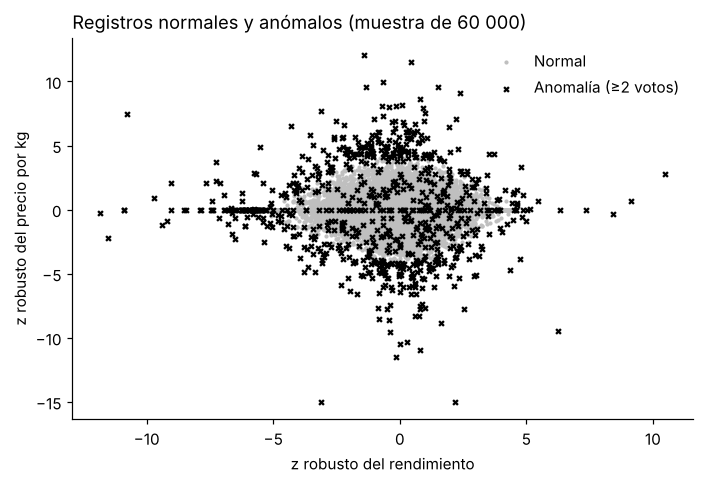

In [10]:
s = d.sample(60000, random_state=1)
fig, ax = plt.subplots(figsize=(6.5, 4.5))
n = s[s.anomalia == 0]; a = s[s.anomalia == 1]
ax.scatter(n.z_rend.clip(-25, 25), n.z_precio.clip(-15, 15), s=3, c='0.75', label='Normal', rasterized=True)
ax.scatter(a.z_rend.clip(-25, 25), a.z_precio.clip(-15, 15), s=10, c='black', marker='x', label='Anomalía (≥2 votos)')
ax.set_xlabel('z robusto del rendimiento'); ax.set_ylabel('z robusto del precio por kg')
ax.set_title('Registros normales y anómalos (muestra de 60 000)', loc='left'); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(f'{CARPETA}/figuras/f2_dispersion.png', dpi=200); plt.show()

## Resultados descriptivos

In [11]:
por_anio = d.groupby('ANIO').agg(registros=('anomalia', 'size'), anomalias=('anomalia', 'sum'))
por_anio['%'] = 100*por_anio.anomalias/por_anio.registros
por_anio.to_csv(f'{CARPETA}/resultados/anomalias_por_anio.csv'); por_anio.round(2).T

ANIO,2015,2016,2017,2018,2019,2021,2022,2023,2024,2025
registros,102727.00,122010.00,125372.00,122888.00,121039.0,120740.00,103881.00,110692.00,163966.00,157091.00
anomalias,1785.00,2256.00,1534.00,2197.00,1810.0,1403.00,1581.00,850.00,1734.00,1226.00
%,1.74,1.85,1.22,1.79,1.5,1.16,1.52,0.77,1.06,0.78


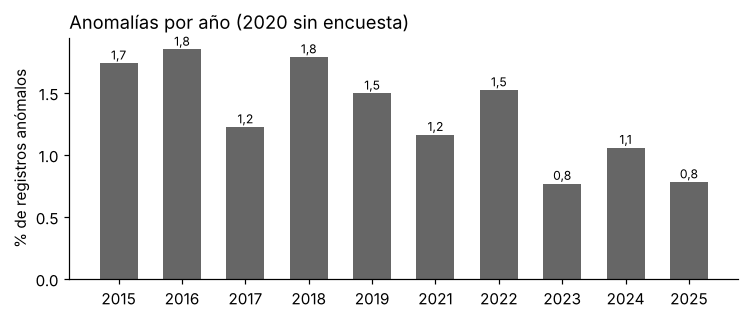

In [12]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(por_anio.index.astype(str), por_anio['%'], color='0.4', width=0.6)
for i, v in enumerate(por_anio['%']): ax.text(i, v + 0.03, f'{v:.1f}'.replace('.', ','), ha='center', fontsize=8)
ax.set_ylabel('% de registros anómalos'); ax.set_title('Anomalías por año (2020 sin encuesta)', loc='left')
plt.tight_layout(); plt.savefig(f'{CARPETA}/figuras/f3_por_anio.png', dpi=200); plt.show()

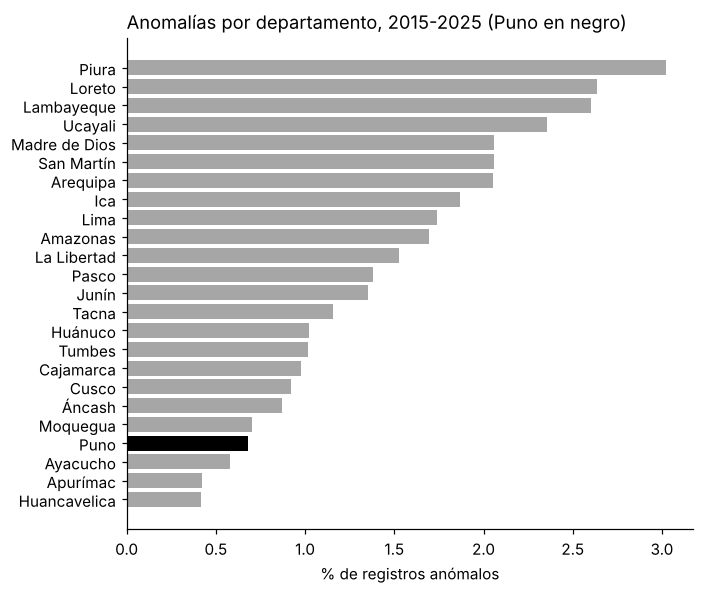

In [13]:
por_dep = d.groupby('departamento').agg(registros=('anomalia', 'size'), anomalias=('anomalia', 'sum'))
por_dep = por_dep[por_dep.registros > 1000]
por_dep['%'] = 100*por_dep.anomalias/por_dep.registros
por_dep = por_dep.sort_values('%'); por_dep.to_csv(f'{CARPETA}/resultados/anomalias_por_departamento.csv')
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.barh(por_dep.index, por_dep['%'], color=['black' if x == 'Puno' else '0.65' for x in por_dep.index])
ax.set_xlabel('% de registros anómalos'); ax.set_title('Anomalías por departamento, 2015-2025 (Puno en negro)', loc='left')
plt.tight_layout(); plt.savefig(f'{CARPETA}/figuras/f4_departamentos.png', dpi=200); plt.show()

In [14]:
por_cultivo = d.groupby('cultivo').agg(registros=('anomalia', 'size'), anomalias=('anomalia', 'sum'))
por_cultivo['%'] = 100*por_cultivo.anomalias/por_cultivo.registros
por_cultivo = por_cultivo[por_cultivo.registros >= 5000].sort_values('%', ascending=False)
por_cultivo.to_csv(f'{CARPETA}/resultados/anomalias_por_cultivo.csv'); por_cultivo.head(10).round(2)

,registros,anomalias,%
cultivo,,,
COCA,5348,316,5.91
ARROZ CASCARA,30689,1697,5.53
CACAO,21455,1158,5.40
OREGANO,5608,290,5.17
MAIZ CHALA,12276,438,3.57
CAFE PERGAMINO,34651,1073,3.10
VID,9560,268,2.80
MAIZ AMARILLO DURO,37152,1024,2.76
TARA,6829,151,2.21


In [15]:
a = d[d.anomalia == 1]
motivo = pd.Series({'Rendimiento muy alto (z > 3,5)': (a.z_rend > 3.5).mean(), 'Rendimiento muy bajo (z < −3,5)': (a.z_rend < -3.5).mean(),
                    'Precio fuera de rango (|z| > 3,5)': (a.z_precio.abs() > 3.5).mean(), 'Superficie fuera de rango (|z| > 3,5)': (a.z_area.abs() > 3.5).mean()})
(100*motivo).round(1).rename('% de las anomalías').to_frame()

,% de las anomalías
"Rendimiento muy alto (z > 3,5)",5.7
"Rendimiento muy bajo (z < −3,5)",19.8
"Precio fuera de rango (|z| > 3,5)",41.2
"Superficie fuera de rango (|z| > 3,5)",21.6


In [16]:
cols = ['ANIO', 'departamento', 'cultivo', 'area_ha', 'prod_kg', 'rend_kg_ha', 'precio_kg', 'z_rend', 'z_precio', 'votos']
top = d[d.anomalia == 1].sort_values(['votos', 'score_if'], ascending=False)
top[cols].head(15).to_csv(f'{CARPETA}/resultados/top_anomalias_nacional.csv', index=False)
top[cols].head(10).round(2)

,ANIO,departamento,cultivo,area_ha,prod_kg,rend_kg_ha,precio_kg,z_rend,z_precio,votos
216354,2016,Tacna,RABANO,0.02,157.50,8750.00,1.33,-4.18,8.52,4
216380,2016,Tacna,RABANO,0.01,85.00,8500.00,0.80,-4.40,4.08,4
216464,2016,Tacna,RABANO,0.06,510.00,8500.00,0.83,-4.40,4.44,4
216635,2016,Tacna,RABANO,0.01,112.00,8960.00,0.85,-3.99,4.66,4
778906,2022,Lima,FRIJOL CANARIO GRANO VERDE,0.00,20.00,5000.00,3.00,7.45,-4.44,4
423112,2018,Lambayeque,PAPRIKA,32.00,416000.00,13000.00,3.07,6.25,-9.43,4
423788,2018,Lambayeque,PAPRIKA,49.00,631916.00,12896.24,3.50,6.18,-8.30,4
216629,2016,Tacna,RABANO,0.01,118.00,9440.00,0.85,-3.59,4.64,4
652773,2021,Junín,FRIJOL PANAMITO GRANO SECO,0.00,0.25,5000.00,10.00,3.72,4.38,4
216630,2016,Tacna,RABANO,0.01,115.00,9583.33,0.80,-3.47,4.12,4


In [17]:
puno = d[d.departamento == 'Puno']
print(f'Puno: {len(puno):,} registros · {puno.anomalia.sum():,} anómalos ({puno.anomalia.mean():.2%})')
pt = puno[puno.anomalia == 1].sort_values(['votos', 'score_if'], ascending=False)
pt[cols].head(15).to_csv(f'{CARPETA}/resultados/top_anomalias_puno.csv', index=False)
display(puno[puno.anomalia == 1].cultivo.value_counts().head(8).rename('anomalías').to_frame().T)
pt[cols].head(8).round(2)

Puno: 79,010 registros · 536 anómalos (0.68%)


cultivo,COCA,CAFE PERGAMINO,PLATANO,CACAO,QUINUA,PAPA NATIVA,AVENA FORRAJERA,YUCA
anomalías,178,57,55,37,24,22,21,15


,ANIO,departamento,cultivo,area_ha,prod_kg,rend_kg_ha,precio_kg,z_rend,z_precio,votos
456919,2018,Puno,CACAO,0.00,2.5,833.33,2.00,0.77,-6.30,4
804485,2022,Puno,CAFE PERGAMINO,0.00,2.5,833.33,5.60,0.92,-4.63,4
453773,2018,Puno,CACAO,0.01,8.0,800.00,1.50,0.67,-8.01,4
695831,2021,Puno,UNCUCHA,0.10,230.0,2300.00,2.17,-4.24,7.96,4
918043,2023,Puno,COCA,0.02,60.0,3000.00,20.83,2.17,3.63,4
918044,2023,Puno,COCA,0.02,36.0,2400.00,25.00,1.87,4.35,4
332468,2017,Puno,COCA,0.01,30.0,3000.00,16.00,1.66,6.71,4
918045,2023,Puno,COCA,0.02,24.0,1600.00,23.33,1.31,4.08,4


In [18]:
d[['ANIO', 'departamento', 'region', 'cultivo', 'area_ha', 'prod_kg', 'rend_kg_ha', 'precio_kg', 'z_rend', 'z_precio', 'z_area',
   'flag_z', 'flag_if', 'flag_km', 'flag_db', 'votos', 'anomalia']].query('votos >= 1').to_csv(f'{CARPETA}/resultados/registros_marcados.csv', index=False)

## Etapa 5 · Validación

No existe una lista oficial de registros erróneos (no hay etiquetas), igual que en el artículo. Por eso validamos de **cuatro formas**, de la más débil a la más fuerte:

1. **Silueta** (lo que hizo el artículo): ¿los grupos están bien separados?
2. **Anomalías conocidas por reglas lógicas** que el modelo **no ve** (por ejemplo, valor de venta ≠ cantidad × precio unitario): ¿los métodos las detectan más que al azar?
3. **Errores inyectados:** metemos a propósito errores típicos de digitación en registros normales y medimos precisión, recall, F1 y AUC (aquí **sí** conocemos la respuesta).
4. **Validación temporal con todo el rango:** el modelo aprende con los años anteriores y se prueba en el año siguiente (2016, 2017, …, 2025).

### 5.1 Silueta

In [19]:
sil = pd.Series(ea.validar_silueta(d, k=K)).rename('Silueta').round(3)
sil.to_csv(f'{CARPETA}/resultados/silueta.csv'); sil.to_frame()

,Silueta
k-Means (k=3),0.263
Normal vs anómalo: Z-score robusto,0.580
Normal vs anómalo: Isolation Forest,0.612
Normal vs anómalo: k-Means,0.659
Normal vs anómalo: DBSCAN,0.641
Normal vs anómalo: Votación (≥2),0.634


### 5.2 Anomalías conocidas por reglas

In [20]:
vr, reglas = ea.validar_reglas(d)
print(reglas.sum().rename('casos').to_string())
vr.to_csv(f'{CARPETA}/resultados/validacion_reglas.csv', index=False)
vr[vr.Casos > 10].round(2)

R1 vendió más de lo que cosechó                 0
R2 cosechó más superficie de la que sembró      3
R3 valor ≠ cantidad × precio                  206


,Regla,Casos,Método,Detectadas (%),Marcadas en el resto (%),Lift
10,R3 valor ≠ cantidad × precio,206,Z-score robusto,8.25,1.66,4.96
11,R3 valor ≠ cantidad × precio,206,Isolation Forest,12.14,1.00,12.16
12,R3 valor ≠ cantidad × precio,206,k-Means,11.65,1.00,11.67
13,R3 valor ≠ cantidad × precio,206,DBSCAN,13.59,1.16,11.75
14,R3 valor ≠ cantidad × precio,206,Votación (≥2),13.59,1.31,10.39


### 5.3 Errores inyectados (1 % de los registros)
* **A)** un cero de más en la producción (× 10)
* **B)** confusión kilogramo ↔ tonelada (× 1 000 o ÷ 1 000)
* **C)** un cero de más en el valor de venta (× 10)

Los registros que ya eran anómalos en los datos reales no se cuentan como falsos positivos.

In [21]:
t = time.time()
vi, por_tipo, _ = ea.validar_inyeccion(limpio, k=K)
print(f'({time.time()-t:.0f} s)')
vi.to_csv(f'{CARPETA}/resultados/validacion_inyeccion.csv'); vi.round(3)

(70 s)


,Precisión,Recall,F1,AUC
Método,,,,
Z-score robusto,0.473,0.865,0.612,0.992
Isolation Forest,0.839,0.309,0.451,0.975
k-Means,0.981,0.652,0.783,0.989
DBSCAN,0.917,0.668,0.773,NaN
Votación (≥2),0.980,0.705,0.820,0.934


In [22]:
por_tipo.columns = list(ea.FLAGS.keys()); por_tipo.index = ['A) producción × 10', 'B) kg ↔ t', 'C) valor × 10']
por_tipo.to_csv(f'{CARPETA}/resultados/recall_por_tipo_error.csv'); print('Recall (%) por tipo de error'); por_tipo.round(1)

Recall (%) por tipo de error


,Z-score robusto,Isolation Forest,k-Means,DBSCAN,Votación (≥2)
A) producción × 10,73.8,8.5,31.1,31.7,40.0
B) kg ↔ t,100.0,36.8,99.7,99.6,99.8
C) valor × 10,85.6,69.1,66.0,73.8,74.7


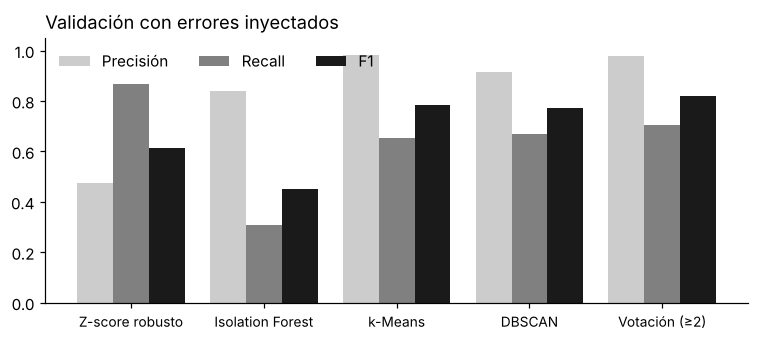

In [23]:
fig, ax = plt.subplots(figsize=(7, 3.2))
x = np.arange(len(vi)); w = 0.27
for j, (m, gris) in enumerate([('Precisión', '0.8'), ('Recall', '0.5'), ('F1', '0.1')]):
    ax.bar(x + (j-1)*w, vi[m], w, color=gris, label=m)
ax.set_xticks(x, vi.index, fontsize=9); ax.set_ylim(0, 1.05); ax.legend(frameon=False, ncol=3, loc='upper left')
ax.set_title('Validación con errores inyectados', loc='left')
plt.tight_layout(); plt.savefig(f'{CARPETA}/figuras/f5_inyeccion.png', dpi=200); plt.show()

### 5.4 Validación temporal (entrenar con años anteriores, probar en el siguiente)

In [24]:
t = time.time()
vt = ea.validar_temporal(limpio, k=K)
print(f'({time.time()-t:.0f} s)')
vt.to_csv(f'{CARPETA}/resultados/validacion_temporal.csv', index=False); vt.round(3)

(167 s)


,Año de prueba,Entrenado con,Registros,Marcados (%),Precisión IF,Recall IF,F1 IF,AUC IF,Precisión Votación,Recall Votación,F1 Votación,AUC Votación
0,2016,2015,122010,2.915,0.965,0.112,0.200,0.969,0.980,0.840,0.905,0.947
1,2017,2015-2016,125372,2.206,0.931,0.162,0.275,0.985,0.945,0.907,0.926,0.968
2,2018,2015-2017,122888,2.994,0.985,0.197,0.329,0.974,0.975,0.874,0.922,0.954
3,2019,2015-2018,121039,2.517,0.979,0.187,0.313,0.969,0.964,0.873,0.916,0.952
4,2021,2015-2019,120740,2.247,0.968,0.128,0.227,0.976,0.974,0.884,0.927,0.957
5,2022,2015-2021,103881,2.745,0.941,0.134,0.235,0.971,0.978,0.867,0.919,0.951
6,2023,2015-2022,110692,1.800,1.000,0.135,0.238,0.972,0.997,0.820,0.900,0.938
7,2024,2015-2023,163966,2.107,0.989,0.139,0.243,0.974,0.977,0.827,0.896,0.942
8,2025,2015-2024,157091,1.877,0.996,0.205,0.339,0.980,0.978,0.852,0.911,0.950


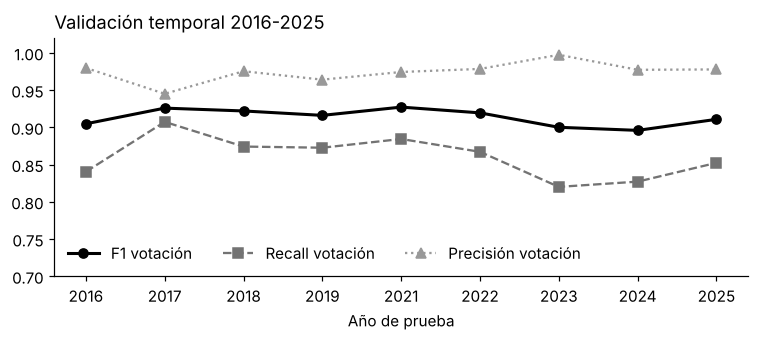

In [25]:
fig, ax = plt.subplots(figsize=(7, 3.2))
xs = vt['Año de prueba'].astype(str)
ax.plot(xs, vt['F1 Votación'], '-o', color='black', lw=2, label='F1 votación')
ax.plot(xs, vt['Recall Votación'], '--s', color='0.45', lw=1.5, label='Recall votación')
ax.plot(xs, vt['Precisión Votación'], ':^', color='0.6', lw=1.5, label='Precisión votación')
ax.set_ylim(0.7, 1.02); ax.set_xlabel('Año de prueba'); ax.legend(frameon=False, ncol=3, loc='lower left')
ax.set_title('Validación temporal 2016-2025', loc='left')
plt.tight_layout(); plt.savefig(f'{CARPETA}/figuras/f6_temporal.png', dpi=200); plt.show()

## Conclusiones

* La limpieza fue decisiva: sin convertir la superficie a hectáreas, el 12 % de los registros parecía anómalo solo por estar en m², topos o yugadas.
* La votación entre 4 métodos marca alrededor del 1,3 % de los registros como anómalos y es el detector más equilibrado.
* La validación no se apoya solo en la silueta (como el artículo): con errores inyectados y con validación año por año, la votación mantiene F1 alto en todo el rango 2016-2025.
* Una anomalía **no es necesariamente un error**: es un registro que conviene revisar (por ejemplo, la coca de la selva de Puno tiene precios legítimamente altos).